In [1]:
import pandas as pd
import scipy.stats
from scipy.ndimage import gaussian_filter1d
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
import umap
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys

# from BWM.Notebooks.DensityMatching import active_lambda
active_lambda = 0.1 # Default value if not imported
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *


plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [2]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca


def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    diff_responses = np.diff(response_tensor_norm, axis=1)
    msd = np.mean(np.abs(diff_responses), axis=(0, 1))
    return msd

directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

regions = ['CP', 'MRN']
region_data = {}

for region in regions:
    pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
        eids=eids,
        directory_path=directory_path,
        region=region,
        mapping='Beryl',
        sigma=2,
        n_steps=100,
        threshold=1,
        min_trials_per_condition=50,
        n_pseudo=25,
        conditions=['choice'],
        event="stimOn_times",
        filter_significant=True,
        significance_threshold=0.
    )

    # Align dimensions if there's a mismatch
    min_neurons = min(pseudo_response_tensor.shape[3], len(neuron_eids))
    pseudo_response_tensor = pseudo_response_tensor[:, :, :, :min_neurons]
    neuron_eids = neuron_eids[:min_neurons]

    # Filter neurons by mean firing rate
    neuron_mask = np.mean(pseudo_response_tensor, axis=(0, 1, 2)) < 35
    pseudo_response_tensor = pseudo_response_tensor[:, :, :, neuron_mask]
    neuron_eids = neuron_eids[neuron_mask]

    msd = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))
    msd_min, msd_max = msd.min(), msd.max()

    X_input = iso_ae_preprocessing(pseudo_response_tensor)
    
    # UMAP projection
    z_neurons = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_input)
    
    # Calculate global limits for consistent axes
    x_min, x_max = z_neurons[:, 0].min(), z_neurons[:, 0].max()
    y_min, y_max = z_neurons[:, 1].min(), z_neurons[:, 1].max()
    padding = 0.05
    x_range = x_max - x_min
    y_range = y_max - y_min
    xlim = (x_min - padding * x_range, x_max + padding * x_range)
    ylim = (y_min - padding * y_range, y_max + padding * y_range)
    
    region_data[region] = {
        'z_neurons': z_neurons,
        'msd': msd,
        'msd_min': msd_min,
        'msd_max': msd_max,
        'neuron_eids': neuron_eids,
        'xlim': xlim,
        'ylim': ylim
    }


Aggregating CP responses across 459 EIDs...


Processing EIDs: 100%|██████████| 459/459 [04:20<00:00,  1.76it/s]


Max conditions: 2, Common conditions found: [(np.float32(-1.0),), (np.float32(1.0),)]
Total neurons collected: 11271
Aggregating MRN responses across 459 EIDs...


Processing EIDs: 100%|██████████| 459/459 [06:42<00:00,  1.14it/s]


Max conditions: 2, Common conditions found: [(np.float32(-1.0),), (np.float32(1.0),)]
Total neurons collected: 12672


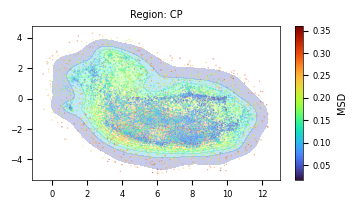

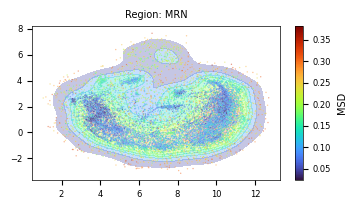

In [3]:
# Plot individual projections for each region
os.makedirs('../../BWM/Figures', exist_ok=True)
for region in regions:
    data = region_data[region]
    fig = plt.figure(figsize=(4, 2))
    ax1 = fig.add_subplot(111)
    
    sc = sns.scatterplot(x=data['z_neurons'][:, 0], y=data['z_neurons'][:, 1], hue=data['msd'], 
                         hue_norm=(data['msd_min'], data['msd_max']), palette='turbo', s=1, alpha=.5, zorder=2, ax=ax1, legend=False)
    sns.kdeplot(x=data['z_neurons'][:, 0], y=data['z_neurons'][:, 1], weights=data['msd'], ax=ax1, fill=True, cmap='turbo', alpha=0.3, zorder=1)
    norm = plt.Normalize(data['msd_min'], data['msd_max'])
    sm = plt.cm.ScalarMappable(cmap='turbo', norm=norm)
    plt.colorbar(sm, ax=ax1, label='MSD')
    ax1.set_xlim(data['xlim'])
    ax1.set_ylim(data['ylim'])
    ax1.set_title(f"Region: {region}")
    
    plt.savefig(f'../../BWM/Figures/UMAP_MSD_Projection_{region}.png', dpi=300, bbox_inches='tight')
    plt.show()


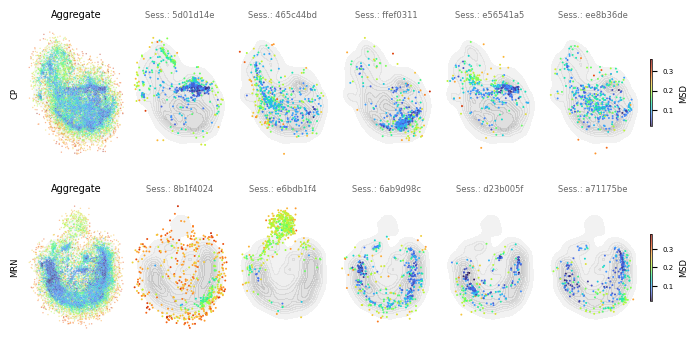

In [13]:
# Create a figure with 2 rows and 6 columns showing the densmap projection 
# with neurons from different EIDs highlighted for each region

fig, axes = plt.subplots(len(regions), 6, figsize=(8, 4), sharex='row', sharey='row')
plt.subplots_adjust(wspace=0, hspace=0.3)

for r_idx, region in enumerate(regions):
    data = region_data[region]
    z_neurons = data['z_neurons']
    msd = data['msd']
    msd_min = data['msd_min']
    msd_max = data['msd_max']
    neuron_eids = data['neuron_eids']
    xlim = data['xlim']
    ylim = data['ylim']
    
    # Get the 5 EIDs with the most neurons
    top_5_eids = [eid for eid, count in Counter(neuron_eids).most_common(5)]
    
    # First subplot in the row: Full distribution colored by MSD
    ax_full = axes[r_idx, 0]
    sns.kdeplot(x=z_neurons[:, 0], y=z_neurons[:, 1], ax=ax_full, fill=True, color='gray', alpha=0.1, zorder=1)
    sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], hue=msd, hue_norm=(msd_min, msd_max), palette='turbo', s=1, alpha=0.5, zorder=2, ax=ax_full, legend=False)
    
    ax_full.set_ylabel(region, fontsize=6)
    ax_full.set_title(f"Aggregate", fontsize=7, y=1.0)
    ax_full.set_xticks([])
    ax_full.set_yticks([])
    ax_full.set_xlim(xlim)
    ax_full.set_ylim(ylim)
    sns.despine(ax=ax_full, left=True, bottom=True)
    
    for i, eid in enumerate(top_5_eids):
        ax = axes[r_idx, i+1]
        # Plot background KDE, weighted by MSD
        sns.kdeplot(x=z_neurons[:, 0], y=z_neurons[:, 1], ax=ax, fill=True, color='gray', alpha=0.2, zorder=1)

        # Highlight neurons from the current EID, colored by MSD
        mask = neuron_eids == eid
        sns.scatterplot(x=z_neurons[mask, 0], y=z_neurons[mask, 1], hue=msd[mask], hue_norm=(msd_min, msd_max), palette='turbo', s=2, alpha=1, linewidth=0, zorder=3, ax=ax, legend=False)
        
        ax.set_title(f"Sess.: {eid[:8]}", fontsize=6, y=1.0,alpha = .6)
        ax.set_xticks([])
        ax.set_yticks([])
        sns.despine(ax=ax, left=True, bottom=True)

    # Add vertical color bar to the right of the last column of each row
    cax = inset_axes(axes[r_idx, -1], width="2.5%", height="50%", loc='center left', bbox_to_anchor=(1.05, 0., 1, 1), bbox_transform=axes[r_idx, -1].transAxes, borderpad=0)
    norm = plt.Normalize(msd_min, msd_max)
    sm = plt.cm.ScalarMappable(cmap='turbo', norm=norm)
    cb = fig.colorbar(sm, cax=cax, orientation='vertical', alpha=0.7)
    cb.set_label('MSD', fontsize=6)
    cb.ax.tick_params(labelsize=5)
    cb.outline.set_linewidth(0.5)

# Save figure 2
plt.savefig('../../BWM/Figures/EID_Highlights_CP_MRN.png', dpi=300, bbox_inches='tight')
plt.show()
